# Preprocesado final del dataset (sin blur)

Para cada imagen seleccionada de `train` y `val`:

1. Recorte de bordes negros de la lupa
2. Cuadrado central + resize a 512x512
3. Color constancy (Shades of Gray, p=6)
4. Eliminación de pelos (DullRazor)
5. Segmentación: Otsu sobre el canal S (directamente sobre la imagen sin blur) + limpieza morfológica

Guarda en `processed/{split}/{clase}/`:
- `<nombre>_preprocessed.png` (RGB 512x512, sin blur, PNG sin pérdidas)
- `<nombre>_mask.png` (0/255, uint8, 512x512, alineada con la anterior)

y un `processed/manifest.csv` con una fila por imagen.

El proceso es **reanudable**: si ya existen los dos archivos de una imagen, no se vuelve a procesar.
La selección usa semilla fija y es estratificada por clase y subtipo, con la proporción real del dataset.

In [1]:
import random
import re
import time
from collections import Counter
from pathlib import Path

import cv2
import numpy as np
import pandas as pd
from joblib import Parallel, delayed
from tqdm.auto import tqdm

# ---------------- Configuración ----------------
ROOT = None              # p. ej. Path("C:/Users/.../Melanoma-Challenge-ML-UdG"); None = buscar automáticamente
OUT_DIR = None           # None = ROOT / "processed"
CLASSES = ["nevus", "others"]
N_TRAIN = None            # None = todas
N_VAL = None              # None = todas
SEED = 42
OVERWRITE = False        # True = reprocesa aunque ya existan los archivos
N_JOBS = 4               # núcleos a usar (-1 = todos, -2 = todos menos uno)

EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"}
TARGET_SIZE = 512
DARK_THR = 35
SOG_P = 6
HAIR_LEN = 17
HAIR_THR = 10
SEG_CHANNEL = "S"        # canal para Otsu: "S", "L", "a", "b", "Cr", "gray"

## Selección estratificada (clase x subtipo, proporción real)

In [2]:
def find_root():
    for p in [Path.cwd(), *Path.cwd().parents]:
        if (p / "train").is_dir() and (p / "val").is_dir():
            return p
    raise FileNotFoundError("No encuentro train/ y val/. Pon ROOT a mano.")


def subtype(path, cls):
    m = re.match(r"[A-Za-z]+", path.stem)
    return m.group(0).lower() if m else cls


def allocate(counts, n):
    """Reparto proporcional (método del mayor resto) que suma exactamente n."""
    total = sum(counts.values())
    exact = {k: n * v / total for k, v in counts.items()}
    alloc = {k: int(np.floor(v)) for k, v in exact.items()}
    rest = n - sum(alloc.values())
    for k in sorted(exact, key=lambda k: exact[k] - alloc[k], reverse=True)[:rest]:
        alloc[k] += 1
    return alloc


def select_images(root, split, n, seed):
    strata = {}
    for c in CLASSES:
        for f in sorted((root / split / c).rglob("*")):
            if f.suffix.lower() in EXTS:
                strata.setdefault((c, subtype(f, c)), []).append(f)
    if n is None:
        return [(split, c, f) for (c, _), fs in strata.items() for f in fs]
    alloc = allocate({k: len(v) for k, v in strata.items()}, n)
    rng = random.Random(seed)
    picked = []
    for k in sorted(strata):
        fs = strata[k][:]
        rng.shuffle(fs)
        picked += [(split, k[0], f) for f in fs[:alloc[k]]]
    return picked


ROOT = Path(ROOT) if ROOT else find_root()
OUT = Path(OUT_DIR) if OUT_DIR else ROOT / "processed"
print("root:", ROOT, "\nout: ", OUT)

jobs = select_images(ROOT, "train", N_TRAIN, SEED) + select_images(ROOT, "val", N_VAL, SEED)
print(f"\nTotal a procesar: {len(jobs)}")
for split in ["train", "val"]:
    cnt = Counter((c, subtype(f, c)) for s, c, f in jobs if s == split)
    print(f"  {split}: {dict(sorted(cnt.items()))}")

root: C:\Users\Lenovo\PycharmProjects\Melanoma-Challenge-ML-UdG 
out:  C:\Users\Lenovo\PycharmProjects\Melanoma-Challenge-ML-UdG\processed

Total a procesar: 18991
  train: {('nevus', 'nev'): 7725, ('others', 'ack'): 520, ('others', 'bcc'): 1993, ('others', 'bkl'): 1574, ('others', 'def'): 143, ('others', 'mel'): 2713, ('others', 'scc'): 376, ('others', 'vac'): 151}
  val: {('nevus', 'nev'): 1931, ('others', 'ack'): 130, ('others', 'bcc'): 498, ('others', 'bkl'): 393, ('others', 'def'): 35, ('others', 'mel'): 678, ('others', 'scc'): 94, ('others', 'vac'): 37}


## Funciones del pipeline

In [3]:
# ---------- Paso 1: bordes negros ----------
def valid_mask(img, dark_thr=DARK_THR):
    gray = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)
    dark = (gray < dark_thr).astype(np.uint8)
    dark = cv2.morphologyEx(dark, cv2.MORPH_OPEN, np.ones((5, 5), np.uint8))
    _, lab = cv2.connectedComponents(dark, connectivity=4)
    border_ids = set(np.unique(np.concatenate([lab[0], lab[-1], lab[:, 0], lab[:, -1]]))) - {0}
    border = np.isin(lab, list(border_ids)).astype(np.uint8)
    m = max(3, int(0.01 * min(img.shape[:2])))
    border = cv2.dilate(border, np.ones((m, m), np.uint8))
    return border == 0


def largest_rectangle(mask):
    H, W = mask.shape
    heights = [0] * W
    best = (0, 0, H, 0, W)
    for y in range(H):
        row = mask[y]
        heights = [h + 1 if row[x] else 0 for x, h in enumerate(heights)]
        stack = []
        for x in range(W + 1):
            h = heights[x] if x < W else 0
            start = x
            while stack and stack[-1][1] >= h:
                s, sh = stack.pop()
                area = sh * (x - s)
                if area > best[0]:
                    best = (area, y - sh + 1, y + 1, s, x)
                start = s
            stack.append((start, h))
    return best[1:]


def crop_black_borders(img, dark_thr=DARK_THR, min_area_frac=0.08):
    H, W = img.shape[:2]
    mask = valid_mask(img, dark_thr)
    scale = min(1.0, 256 / max(H, W))
    small = cv2.resize(mask.astype(np.uint8), None, fx=scale, fy=scale,
                       interpolation=cv2.INTER_NEAREST).astype(bool)
    y0, y1, x0, x1 = largest_rectangle(small)
    y0, y1 = int(np.ceil(y0 / scale)), int(np.floor(y1 / scale))
    x0, x1 = int(np.ceil(x0 / scale)), int(np.floor(x1 / scale))
    fallback = False
    if (y1 - y0) * (x1 - x0) < min_area_frac * H * W:
        y0, y1, x0, x1 = 0, H, 0, W            # fallback: no se recorta
        fallback = True
    return img[y0:y1, x0:x1], (y0, y1, x0, x1), fallback


# ---------- Paso 2: cuadrado + resize ----------
def square_resize(img, size=TARGET_SIZE):
    H, W = img.shape[:2]
    s = min(H, W)
    y0, x0 = (H - s) // 2, (W - s) // 2
    sq = img[y0:y0 + s, x0:x0 + s]
    interp = cv2.INTER_AREA if s > size else cv2.INTER_CUBIC
    return cv2.resize(sq, (size, size), interpolation=interp)


# ---------- Paso 3: Shades of Gray ----------
def shades_of_gray(img, p=SOG_P):
    x = img.astype(np.float32)
    illum = np.power(np.mean(np.power(x, p), axis=(0, 1)), 1.0 / p)
    illum = illum / np.linalg.norm(illum)
    out = x / (illum * np.sqrt(3))
    return np.clip(out, 0, 255).astype(np.uint8)


# ---------- Paso 4: pelos (DullRazor) ----------
def line_kernel(length, angle_deg):
    k = np.zeros((length, length), np.uint8)
    c = length // 2
    a = np.deg2rad(angle_deg)
    dx, dy = np.cos(a) * c, np.sin(a) * c
    cv2.line(k, (int(round(c - dx)), int(round(c + dy))), (int(round(c + dx)), int(round(c - dy))), 1, 1)
    return k


def hair_mask(img, length=HAIR_LEN, thr=HAIR_THR, angles=range(0, 180, 30),
              min_len=25, min_aspect=3.5, dilate_iter=2):
    gray = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)
    bh = np.maximum.reduce([cv2.morphologyEx(gray, cv2.MORPH_BLACKHAT, line_kernel(length, a)) for a in angles])
    raw = (bh > thr).astype(np.uint8)
    n, lab, stats, _ = cv2.connectedComponentsWithStats(raw, connectivity=8)
    keep = np.zeros_like(raw)
    for i in range(1, n):
        x, y, w, h, area = stats[i]
        if area < 15:
            continue
        sub = lab[y:y + h, x:x + w] == i
        pts = np.column_stack(np.where(sub))[:, ::-1].astype(np.float32)
        (_, _), (rw, rh), _ = cv2.minAreaRect(pts)
        length_c, width_c = max(rw, rh), max(min(rw, rh), 1.0)
        elongated = length_c >= min_len and length_c / width_c >= min_aspect
        thin_curve = max(w, h) >= 2 * min_len and area / (w * h) < 0.2
        if elongated or thin_curve:
            keep[y:y + h, x:x + w][sub] = 1
    return cv2.dilate(keep, np.ones((3, 3), np.uint8), iterations=dilate_iter)


def remove_hair(img):
    m = hair_mask(img)
    return cv2.inpaint(img, m * 255, 3, cv2.INPAINT_TELEA), m


# ---------- Paso 5: segmentación Otsu(canal) sin blur ----------
def get_channel(img, name):
    """Calcula solo el canal pedido (más rápido que calcular todos)."""
    if name == "gray":
        return cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)
    if name in ("L", "a", "b"):
        return cv2.cvtColor(img, cv2.COLOR_RGB2LAB)[..., "Lab".index(name)]
    if name == "Cr":
        return cv2.cvtColor(img, cv2.COLOR_RGB2YCrCb)[..., 1]
    if name == "S":
        return cv2.cvtColor(img, cv2.COLOR_RGB2HSV)[..., 1]
    raise ValueError(f"Canal no soportado: {name}")


def border_ring(shape, frac=0.08):
    H, W = shape
    m = int(frac * min(H, W))
    ring = np.ones((H, W), bool)
    ring[m:H - m, m:W - m] = False
    return ring


def otsu_mask(ch):
    ch = cv2.normalize(ch, None, 0, 255, cv2.NORM_MINMAX)
    _, bw = cv2.threshold(ch, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    bw = bw > 0
    if bw[border_ring(bw.shape)].mean() > 0.5:      # el "foreground" es la clase que menos toca el borde
        bw = ~bw
    return bw


def clean_mask(bw, open_k=5, close_k=15, center_sigma=0.35):
    ell = lambda n: cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (n, n))
    m = bw.astype(np.uint8)
    m = cv2.morphologyEx(m, cv2.MORPH_OPEN, ell(open_k))
    m = cv2.morphologyEx(m, cv2.MORPH_CLOSE, ell(close_k))
    n, lab, stats, cent = cv2.connectedComponentsWithStats(m, connectivity=8)
    if n == 1:
        return np.zeros_like(bw)
    S = m.shape[0]
    c = np.array([m.shape[1] / 2, m.shape[0] / 2])
    score = [stats[i, cv2.CC_STAT_AREA] * np.exp(-(np.linalg.norm(cent[i] - c) / (center_sigma * S)) ** 2)
             for i in range(1, n)]
    best = int(np.argmax(score)) + 1
    m = (lab == best).astype(np.uint8)
    cnts, _ = cv2.findContours(m, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    filled = np.zeros_like(m)
    cv2.drawContours(filled, cnts, -1, 1, thickness=-1)
    return filled.astype(bool)


def segment(img, channel=SEG_CHANNEL):
    return clean_mask(otsu_mask(get_channel(img, channel)))


# ---------- Control de calidad de la máscara (solo flag, no descarta) ----------
def mask_qc(mask, min_frac=0.01, max_frac=0.60, min_solidity=0.75):
    area_frac = float(mask.mean())
    touches = bool(mask[0].any() or mask[-1].any() or mask[:, 0].any() or mask[:, -1].any())
    solidity = np.nan
    if mask.any():
        cnts, _ = cv2.findContours(mask.astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
        cnt = max(cnts, key=cv2.contourArea)
        hull_area = cv2.contourArea(cv2.convexHull(cnt))
        solidity = float(cv2.contourArea(cnt) / hull_area) if hull_area > 0 else np.nan
    ok = (min_frac <= area_frac <= max_frac) and not touches and (solidity >= min_solidity)
    return {"mask_area_frac": area_frac, "mask_touches_border": touches,
            "mask_solidity": solidity, "seg_ok": bool(ok)}


# ---------- Pipeline completo ----------
def preprocess(img):
    cropped, rect, fallback = crop_black_borders(img)
    resized = square_resize(cropped)
    color_const = shades_of_gray(resized)
    img_feat, hmask = remove_hair(color_const)       # sin blur
    mask = segment(img_feat)                         # Otsu(S) directo sobre img_feat
    return img_feat, mask, rect, float(hmask.mean()), fallback

## Procesado y guardado (paralelo y reanudable)

In [4]:
def read_rgb(path):
    data = np.fromfile(str(path), dtype=np.uint8)
    bgr = cv2.imdecode(data, cv2.IMREAD_COLOR)
    return cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)


def write_png(path, arr):
    ok, buf = cv2.imencode(".png", arr)
    if not ok:
        raise IOError(f"No se pudo codificar {path}")
    buf.tofile(str(path))


def process_one(split, cls, path, out_root, overwrite):
    cv2.setNumThreads(1)                              # evita sobresuscripción con joblib
    out_dir = Path(out_root) / split / cls
    out_dir.mkdir(parents=True, exist_ok=True)
    p_img = out_dir / f"{path.stem}_preprocessed.png"
    p_msk = out_dir / f"{path.stem}_mask.png"
    row = {"split": split, "class": cls, "subtype": subtype(path, cls), "name": path.stem,
           "src": str(path), "preprocessed": str(p_img), "mask": str(p_msk)}
    try:
        if p_img.exists() and p_msk.exists() and not overwrite:
            mask = cv2.imdecode(np.fromfile(str(p_msk), np.uint8), cv2.IMREAD_GRAYSCALE) > 0
            row.update(mask_qc(mask))
            row["status"] = "skipped"
            return row
        img = read_rgb(path)
        img_feat, mask, (y0, y1, x0, x1), hair_frac, fallback = preprocess(img)
        write_png(p_img, cv2.cvtColor(img_feat, cv2.COLOR_RGB2BGR))
        write_png(p_msk, (mask.astype(np.uint8) * 255))
        row.update({"orig_h": img.shape[0], "orig_w": img.shape[1],
                    "crop_y0": y0, "crop_y1": y1, "crop_x0": x0, "crop_x1": x1,
                    "crop_fallback": fallback, "hair_frac": hair_frac, **mask_qc(mask), "status": "ok"})
    except Exception as e:                            # una imagen rota no para el lote
        row["status"] = f"error: {e}"
    return row


t0 = time.time()
gen = Parallel(n_jobs=N_JOBS, return_as="generator")(
    delayed(process_one)(s, c, f, OUT, OVERWRITE) for s, c, f in jobs)
rows = [r for r in tqdm(gen, total=len(jobs))]
print(f"\nTiempo total: {time.time() - t0:.0f}s  ({(time.time() - t0) / max(len(jobs), 1):.2f} s/img de reloj)")

  0%|          | 0/18991 [00:00<?, ?it/s]


Tiempo total: 996s  (0.05 s/img de reloj)


## Manifest y resumen

In [5]:
new = pd.DataFrame(rows)
manifest_path = OUT / "manifest.csv"
if manifest_path.exists():           # conserva datos completos (hair_frac, recorte...) de ejecuciones previas
    old = pd.read_csv(manifest_path)
    new = pd.concat([old, new], ignore_index=True)
    new["_skipped"] = new["status"].eq("skipped")          # las filas 'skipped' tienen menos datos: pierden prioridad
    new = (new.sort_values("_skipped", kind="stable")
              .drop_duplicates(subset=["split", "class", "name"], keep="first")
              .drop(columns="_skipped"))
new = new.sort_values(["split", "class", "name"]).reset_index(drop=True)
new.to_csv(manifest_path, index=False)
print("manifest:", manifest_path, f"({len(new)} filas)\n")

print(new["status"].str.split(":").str[0].value_counts().to_string(), "\n")
print(new.groupby(["split", "class"]).agg(n=("name", "size"),
                                          seg_ok=("seg_ok", "mean"),
                                          area_frac_med=("mask_area_frac", "median"),
                                          hair_frac_med=("hair_frac", "median")).round(3).to_string())

if "crop_fallback" in new:
    print("\nSin recortar (fallback):", int(new["crop_fallback"].fillna(False).sum()))

errs = new[new["status"].str.startswith("error")]
if len(errs):
    print("\nImágenes con error:")
    print(errs[["split", "class", "name", "status"]].to_string(index=False))

manifest: C:\Users\Lenovo\PycharmProjects\Melanoma-Challenge-ML-UdG\processed\manifest.csv (18991 filas)

status
ok    18991 

                 n  seg_ok  area_frac_med  hair_frac_med
split class                                             
train nevus   7725   0.726          0.175          0.018
      others  7470   0.350          0.192          0.016
val   nevus   1931   0.735          0.173          0.017
      others  1865   0.362          0.193          0.017

Sin recortar (fallback): 1


## (Opcional) Revisión visual rápida: 12 imágenes al azar + las marcadas `seg_ok == False`

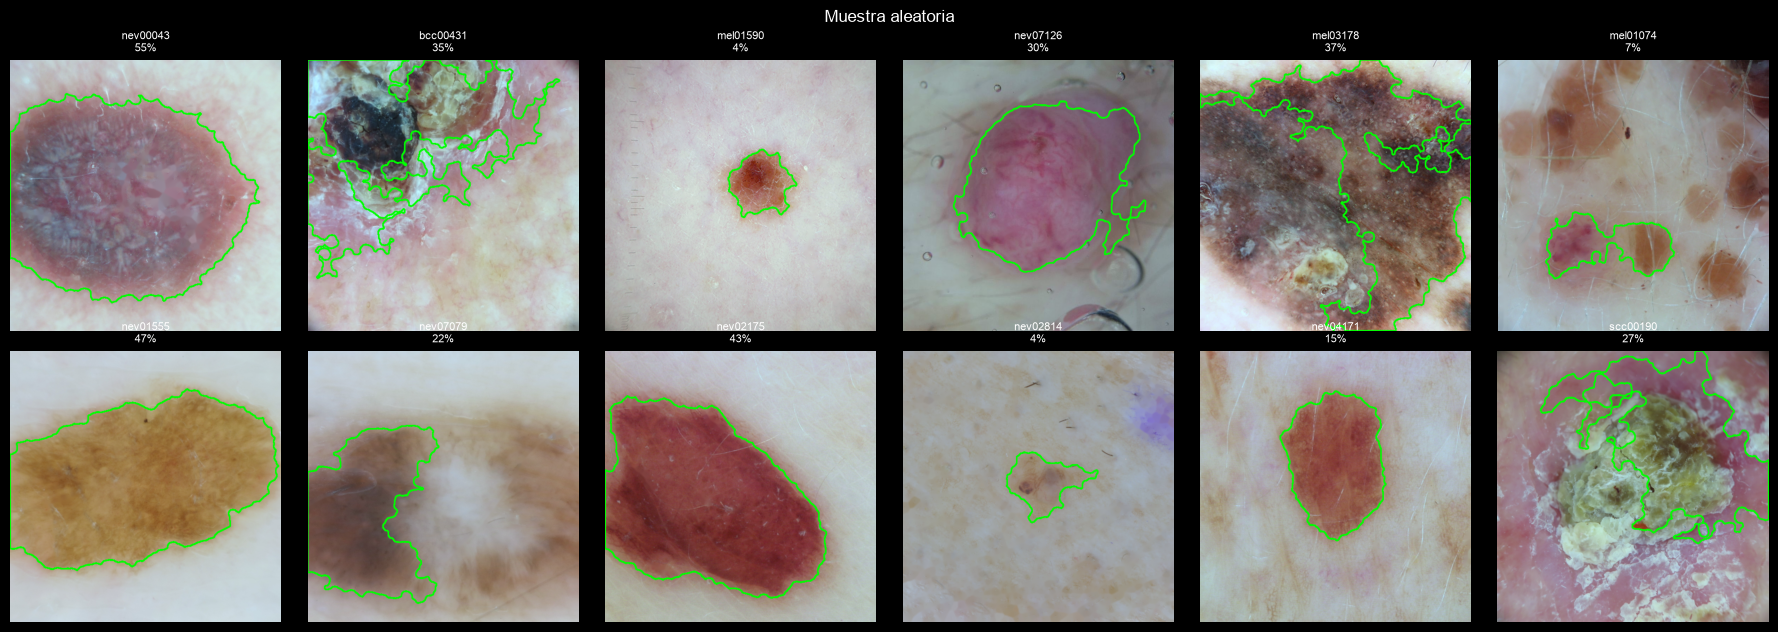

8669 imágenes con seg_ok == False (se muestran hasta 24)


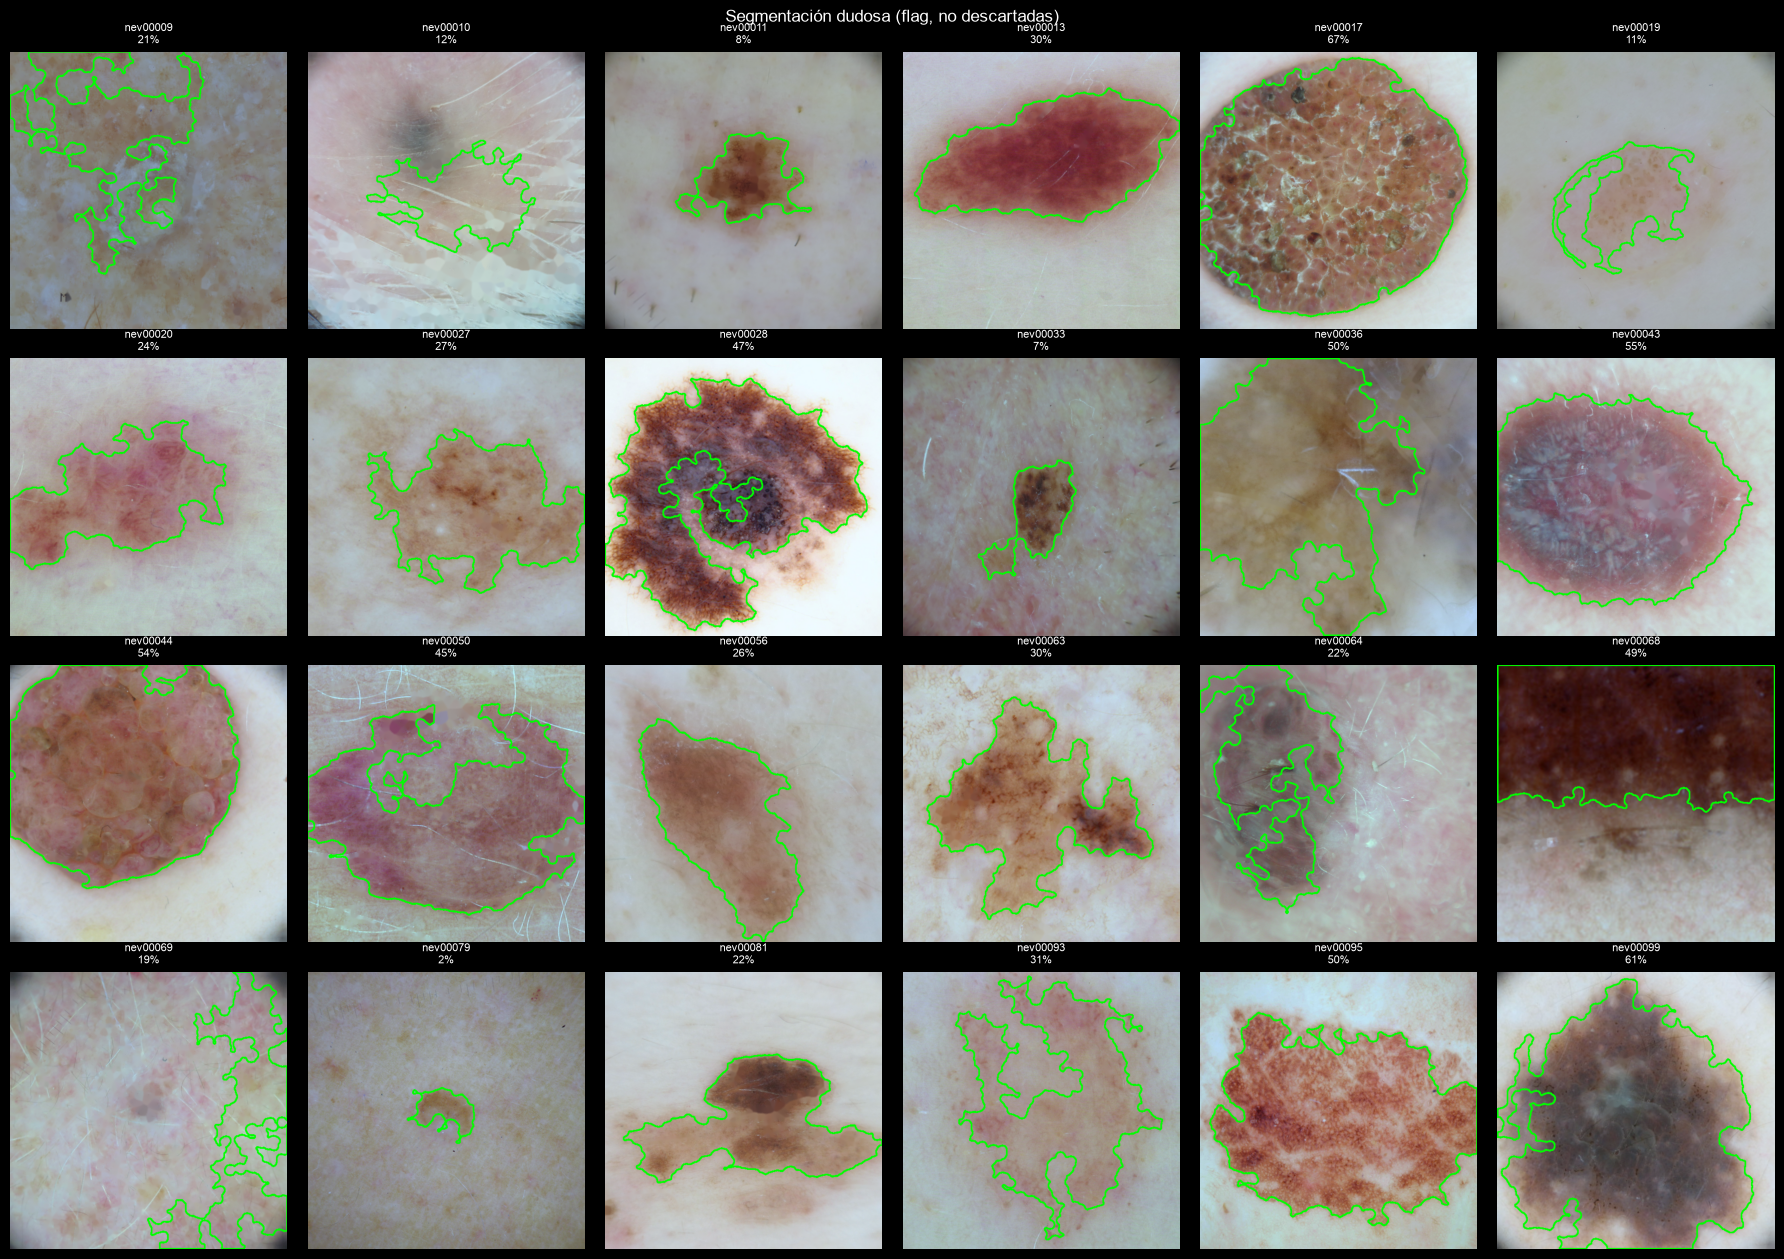

In [6]:
import matplotlib.pyplot as plt


def contour_overlay(img, mask, color=(0, 255, 0), thick=2):
    out = img.copy()
    cnts, _ = cv2.findContours(mask.astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
    cv2.drawContours(out, cnts, -1, color, thick)
    return out


def contact_sheet(df, ncols=6, title=""):
    n = len(df)
    nrows = int(np.ceil(n / ncols))
    fig, axs = plt.subplots(nrows, ncols, figsize=(3 * ncols, 3.2 * nrows), squeeze=False)
    for a in axs.ravel():
        a.axis("off")
    for a, (_, r) in zip(axs.ravel(), df.iterrows()):
        img = read_rgb(r["preprocessed"])
        m = cv2.imdecode(np.fromfile(r["mask"], np.uint8), cv2.IMREAD_GRAYSCALE) > 0
        a.imshow(contour_overlay(img, m))
        a.set_title(f"{r['name']}\n{100 * r['mask_area_frac']:.0f}%", fontsize=8)
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()


ok_rows = new[new["status"].isin(["ok", "skipped"])]
contact_sheet(ok_rows.sample(min(12, len(ok_rows)), random_state=SEED), title="Muestra aleatoria")
bad = ok_rows[~ok_rows["seg_ok"]]
print(f"{len(bad)} imágenes con seg_ok == False (se muestran hasta 24)")
if len(bad):
    contact_sheet(bad.head(24), title="Segmentación dudosa (flag, no descartadas)")